Exercises:
- **E01: Tune the hyperparameters of the training to beat my best validation loss of 2.2**
- E02: I was not careful with the intialization of the network in this video. (1) What is the loss you'd get if the predicted probabilities at initialization were perfectly uniform? What loss do we achieve? (2) Can you tune the initialization to get a starting loss that is much more similar to (1)?
- E03: Read the Bengio et al 2003 paper (link above), implement and try any idea from the paper. Did it work?

In [16]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [17]:
words = open('names.txt', 'r').read().splitlines()
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


### 修改了下面的部分代码，把 block_size, batch_size, n_embd, n_hidden, max_steps 都挪到了外面方便调试不同参数

In [97]:
# build the dataset
block_size = 3    # 上下文长度
batch_size = 32   # 每步抽取的样本数
n_embd = 10       # 每个字符的 embedding 维度
n_hidden = 200    # 隐藏层大小
max_steps = 50000

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182691, 3]) torch.Size([182691])
torch.Size([22793, 3]) torch.Size([22793])
torch.Size([22662, 3]) torch.Size([22662])


In [98]:
g = torch.Generator().manual_seed(2147483647)
vocab_size = len(stoi)

C = torch.randn((vocab_size, n_embd), generator=g)
W1 = torch.randn((block_size * n_embd, n_hidden), generator=g)
b1 = torch.randn(n_hidden, generator=g)
W2 = torch.randn((n_hidden, vocab_size), generator=g)
b2 = torch.randn(vocab_size, generator=g)

parameters = [C, W1, b1, W2, b2]

sum(p.nelement() for p in parameters) # number of parameters in total

11897

In [99]:
for p in parameters:
  p.requires_grad = True

lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

lri = []
lossi = []
stepi = []

In [100]:
for i in range(max_steps):
  ix = torch.randint(0, Xtr.shape[0], (batch_size,))

  emb = C[Xtr[ix]]                 # (batch_size, block_size, n_embd)
  h = torch.tanh(emb.flatten(1) @ W1 + b1) # flatten(1) 保留第 0 维的样本数，把后面的维度合并
  logits = h @ W2 + b2
  loss = F.cross_entropy(logits, Ytr[ix])

  #print(loss.item())
  
  # backward pass
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  #lr = lrs[i]
  lr = 0.1 if i < max_steps/2 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track stats
  #lri.append(lre[i])
  stepi.append(i)
  lossi.append(loss.log10().item())

#print(loss.item())

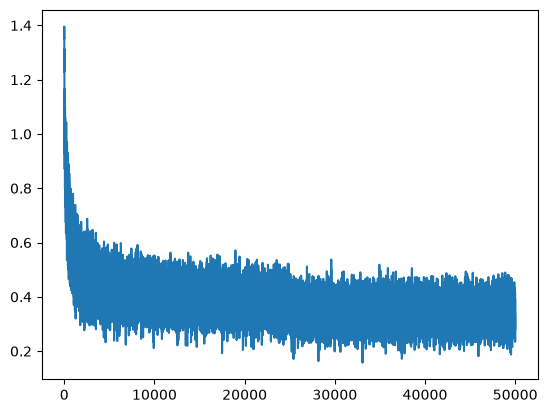

In [101]:
plt.plot(stepi, lossi)

In [102]:
emb = C[Xtr] # (32, 3, 2)
h = torch.tanh(emb.flatten(1) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.2285, grad_fn=<NllLossBackward0>)

In [103]:
emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.flatten(1) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.2566, grad_fn=<NllLossBackward0>)

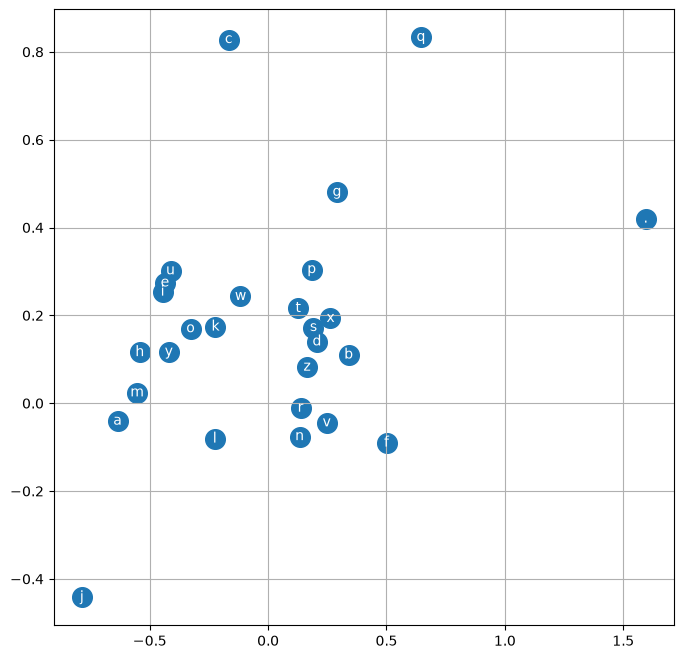

In [104]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [105]:
context = [0] * block_size
C[torch.tensor([context])].shape

torch.Size([1, 3, 10])

In [106]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

eriah.
myaz.
keel.
nihahalarethastendraeg.
aderedielin.
shyanea.
eden.
esoraar.
katelostara.
noshibergini.
jest.
jairethikonnteuson.
brence.
raylene.
eha.
kayjahstonda.
halina.
yarsun.
zajahven.
ell.


---
- 改 hidden 大小对于这个任务来说不能带来一个明显的提升， 可能对于本任务来说 200 hidden 大小已经可以满足要求
- 改 embedding 15, batch_size 128, block_size 4 对任务可以有一个明显的提升
- 对于 block_size 改到 4 之后， 对于一个batch来说的loss看不到很明显的下降，浮动比原来也大很多。 但是最终训练后的 loss 相比 3 有一定的下降。